# PV End of Service Estimates for IEA PVPS and EPRI
This journal is the math for PV ICE end of service quantities estimates for multiple publications, including an EPRI rate of recycling report and an IEA PVPS report. 

Deployment (historical and future):
- IEA PVPS Task 1 for historical PV deployment by country, most recent is published Nov 2026
- LBNL utility scale PV report for CdTe installs in the U.S., plus Wood Mackenzie sector-wise installs to create a %CdTe
- 

Scenarios include: 
- PV fleets degradation, by PVCZ [Karin et al 2020] "PVCZdeg"
- IRENA early loss, regular loss, "IRENAearly", "IRENAreg"
- PV Fleets median degradation, "DegMedian"

In [1]:
import numpy as np
import pandas as pd
import os,sys
from pathlib import Path
import matplotlib.pyplot as plt
import re

plt.rcParams.update({'font.size': 18})
plt.rcParams['figure.figsize'] = (10, 6)

cwd = os.getcwd() #grabs current working directory

testfolder = cwd #str(Path().resolve().parent.parent / 'PV_ICE' / 'TEMP' / 'PVPS_EoSEstimates_Nov2026')
#inputfolder = str(Path().resolve().parent.parent / 'PV_ICE' / 'TEMP')
baselinesfolder = str(Path().resolve().parent.parent /'PV_ICE' / 'baselines')
supportMatfolder = str(Path().resolve().parent.parent / 'PV_ICE' / 'baselines' / 'SupportingMaterial')

if not os.path.exists(testfolder):
    os.makedirs(testfolder)

In [2]:
#load in a baseline and materials for modification
import PV_ICE

PV_ICE.__version__

'0.4.3'

In [144]:
#pull in files needed for the multiple scenario runs
scennames = ['test'] #['PVCZdeg'] #"IRENAearly", "IRENAreg", "DegMedian"
countries = ['FRANCE','SPAIN','GERMANY','ITALY','NETHERLANDS'] #'USA',

MATERIALS = ['glass','silver','silicon', 'copper', 'aluminium_frames', 'encapsulant', 'backsheet']
MATERIALS_CdTe = ['cadmium', 'tellurium', 'glass_cdte', 'aluminium_frames_cdte', 'encapsulant_cdte', 'copper_cdte']
moduleFile_m_Si = os.path.join(baselinesfolder, 'baseline_modules_mass_World.csv')
moduleFile_m_CdTe = os.path.join(baselinesfolder, 'baseline_modules_mass_US_CdTe.csv')

#### Prep the files

In [8]:
deploy_CdTe_pct = pd.read_csv(os.path.join(baselinesfolder, 'baseline_deploy_SivsTF_marketshare_allsector.csv'), index_col='year')
deployment_bycountry_raw = pd.read_csv(os.path.join(testfolder, 'IEAPVPS-Task1-GlobalInstallsbyCountry_MWdc.csv'), index_col='Year')
PVCZ_deg_rates = pd.read_csv(os.path.join(testfolder, 'PVFleetsDeg_byPVCZ.csv'))

In [9]:
deployment_bycountry_raw.head(4)

,AUSTRALIA,AUSTRIA,BELGIUM,CANADA,CHINA,DENMARK,FINLAND,FRANCE,GERMANY,INDIA,...,THAILAND,TÜRKIYE,UK,USA,REST OF EU COUNTRIES,TOTAL IEA PVPS,BRAZIL,PAKISTAN,TOTAL NON IEA PVPS,TOTAL
Year,,,,,,,,,,,,,,,,,,,,,
1992,7,1,0,1,0,0,0,2,6,0,...,0,0,0,0,0,50,0,0,0,50
1993,2,0,0,0,0,0,0,0,3,0,...,0,0,0,0,0,16,0,0,0,16
1994,2,0,0,0,0,0,0,0,3,0,...,0,0,0,0,0,16,0,0,9,25
1995,2,0,0,0,0,0,0,1,6,0,...,0,0,0,0,0,24,0,0,0,25


In [6]:
deploy_CdTe_pct.head(4)

,% CdTe,%Silicon
year,,
1995,0.0,100.0
1996,0.0,100.0
1997,0.0,100.0
1998,0.0,100.0


In [7]:
PVCZ_deg_rates.head(4)

,Years before reaching 80%,Degradation Rate,USA PV Fleets,USA PV Fleets (H method),France (T3:T4),Italy (T4:T5),Spain (T4:T5:T6),Germany (T3),Netherlands (T3)
0,100,-0.01,0.00,9.06,9.520,7.050,8.15,10.34,10.34
1,100,-0.20,18.42,12.71,12.735,9.720,11.61,15.38,15.38
2,50,-0.40,10.06,15.26,14.550,15.895,15.40,14.40,14.40
3,33,-0.60,12.30,14.19,12.705,15.785,14.65,12.37,12.37


Let's start simple, run all the countries with 0.7% deg

In [11]:
baselinesfolder

'C:\\Users\\hmirletz\\Documents\\GitHub\\PV_ICE\\PV_ICE\\baselines'

In [14]:
sim1 = PV_ICE.Simulation(name='sim1', path=testfolder)
for scen in countries:
    sim1.createScenario(name=scen, massmodulefile=moduleFile_m_Si)
    for mat in range (0, len(MATERIALS)):
        matbaseline_m = os.path.join(baselinesfolder,'baseline_material_mass_'+MATERIALS[mat]+'.csv')
        #matbaseline_e = os.path.join(baselinesfolder,'baseline_material_energy_'+MATERIALS[mat]+'.csv')
        sim1.scenario[scen].addMaterial(MATERIALS[mat], massmatfile=matbaseline_m)#, energymatfile=matbaseline_e)

path = C:\Users\hmirletz\Documents\GitHub\PV_ICE\Studies\PVPS_EoSEstimates_Nov2026
Baseline folder directed to default:  C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\baselines
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']


In [44]:
#simulation wide modficiations
sim1.scenMod_noCircularity()
sim1.trim_Years(startYear=1995, endYear=2025) #dont yet need projection into the future, only looking at waste in 2023, 2024, 2025

Trimming and extending  USA
No energy data loaded. Skipping for all next scenarios and materials
USA backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  FRANCE
FRANCE backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  SPAIN
SPAIN backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  GERMANY
GERMANY backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  ITALY
ITALY backsheet : Data trimmed for Mass, years now encompass  1995  to  2025
Trimming and extending  NETHERLANDS
NETHERLANDS backsheet : Data trimmed for Mass, years now encompass  1995  to  2025


In [45]:
sim1.scenario.keys()

dict_keys(['USA', 'FRANCE', 'SPAIN', 'GERMANY', 'ITALY', 'NETHERLANDS'])

In [47]:
for scen in countries:
    sim1.modifyScenario(scen, 'new_Installed_Capacity_[MW]', 0.0, start_year=1995) #deployment_bycountry_raw.loc[1995:,scen]
    sim1.modifyScenario(scen, 'new_Installed_Capacity_[MW]', deployment_bycountry_raw.loc[1995:,scen], start_year=1995)

In [50]:
sim1.scenario['USA'].dataIn_m.tail()

,year,new_Installed_Capacity_[MW],mod_eff,mod_reliability_t50,mod_reliability_t90,mod_degradation,mod_lifetime,mod_MFG_eff,mod_Repair,mod_MerchantTail,...,mod_EOL_pg1_landfill,mod_EOL_pg2_stored,mod_EOL_pg3_reMFG,mod_EOL_pg4_recycled,mod_EOL_reMFG_yield,mod_EOL_sp_reMFG_recycle,mod_EOL_pb1_landfill,mod_EOL_pb2_stored,mod_EOL_pb3_reMFG,mod_EOL_pb4_recycled
26,2021,24819.0,20.900000,39.0,42.0,0.75,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0
27,2022,22695.0,21.100000,39.0,42.0,0.60,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0
28,2023,34892.0,21.860752,39.0,42.0,0.60,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0
29,2024,47077.0,22.318415,39.0,42.0,0.60,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0
30,2025,3200.0,22.648932,39.0,42.0,0.60,35.0,98,0.0,0.0,...,100.0,0.0,0.0,0.0,0,0.0,100.0,0.0,0.0,0.0


In [45]:
#Lifetime and Degradation
#values taken from lifetime vs recycling paper
#degradation rate:
#sim1.modifyScenario('test', 'mod_degradation',0.2, start_year=2000) 
#sim1.modifyScenario('test', 'mod_lifetime', 50, start_year=2000) 
#sim1.modifyScenario('test', 'new_Installed_Capacity_[MW]', 0.0, start_year=1995) 
#sim1.modifyScenario('test', 'mod_eff', 17.0, start_year=1995) 

#sim1.scenMod_perfectRecycling()
#sim1.scenMod_noCircularity()

In [52]:
sim1.calculateMassFlow()

>>>> Calculating Material Flows <<<<

Working on Scenario:  USA
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silver
==> Working on Material :  silicon
==> Working on Material :  copper
==> Working on Material :  aluminium_frames
==> Working on Material :  encapsulant
==> Working on Material :  backsheet
Working on Scenario:  FRANCE
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silver
==> Working on Material :  silicon
==> Working on Material :  copper
==> Working on Material :  aluminium_frames
==> Working on Material :  encapsulant
==> Working on Material :  backsheet
Working on Scenario:  SPAIN
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silver
==> Working on Material :  silicon
==> Working on Material :  copper
==> Working on Material :  aluminium

In [53]:
sim1.scenario['USA'].dataOut_m.keys()

Index(['Area', 'Cumulative_Active_Area', 'EOL_BadStatus', 'EOL_Landfill0',
       'EOL_PATHS', 'EOL_PG', 'Effective_Capacity_[W]', 'Landfill_0_ProjLife',
       'MerchantTail_Area', 'MerchantTail_[W]', 'ModuleTotal_MFG', 'P2_stored',
       'P3_reMFG', 'P4_recycled', 'PB1_landfill', 'PB2_stored', 'PB3_reMFG',
       'PB3_reMFG_unyield', 'PB3_reMFG_yield', 'PB4_recycled', 'PG1_landfill',
       'PG2_stored', 'PG3_reMFG', 'PG3_reMFG_unyield', 'PG3_reMFG_yield',
       'PG4_recycled', 'Power_Degraded_[W]', 'Repaired_Area', 'Repaired_[W]',
       'Resold_Area', 'Resold_[W]', 'WeibullParams',
       'Yearly_Sum_Area_EOLby_Degradation', 'Yearly_Sum_Area_EOLby_Failure',
       'Yearly_Sum_Area_EOLby_ProjectLifetime', 'Yearly_Sum_Area_PathsBad',
       'Yearly_Sum_Area_PathsGood', 'Yearly_Sum_Area_atEOL',
       'Yearly_Sum_Power_EOLby_Degradation', 'Yearly_Sum_Power_EOLby_Failure',
       'Yearly_Sum_Power_EOLby_ProjectLifetime', 'Yearly_Sum_Power_PathsBad',
       'Yearly_Sum_Power_PathsGood

Text(0.5, 1.0, 'Effective capacity in GW')

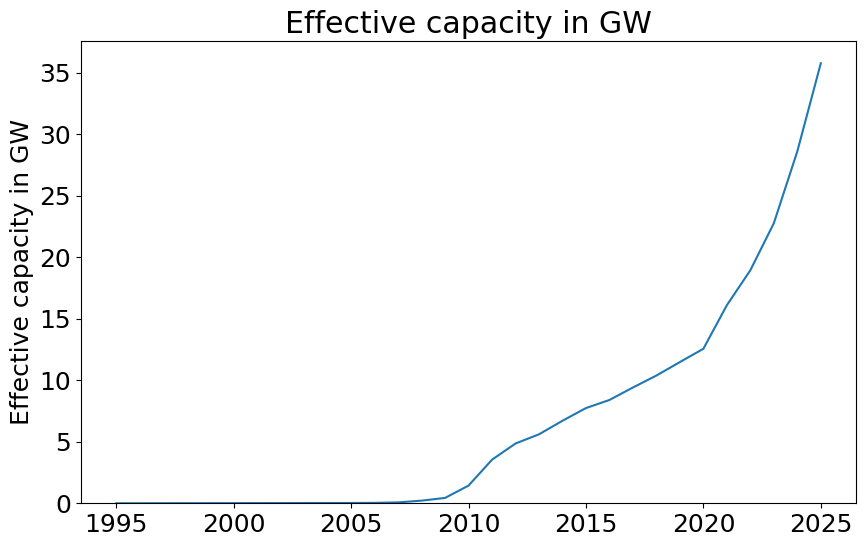

In [54]:
plt.plot(sim1.scenario['FRANCE'].dataIn_m['year'], sim1.scenario['FRANCE'].dataOut_m['Effective_Capacity_[W]']/1e9)
plt.ylim(0,)
plt.ylabel('Effective capacity in GW')
plt.title('Effective capacity in GW')
#plt.plot(sim1.scenario['base'].dataIn_m['new_Installed_Capacity_[MW]'])

In [55]:
sim1_annual, sim1_cumu = sim1.aggregateResults()

C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:2164: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  USyearly[nicekey+'_'+mat+'_'+self.name+'_'+scen] = self.scenario[scen].material[mat].matdataOut_m[keywd]
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:2164: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  USyearly[nicekey+'_'+mat+'_'+self.name+'_'+scen] = self.scenario[scen].material[mat].matdataOut_m[keywd]
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\mai

In [57]:
sim1_cumu.keys()

Index(['VirginStock_glass_sim1_USA_[Tonnes]',
       'VirginStock_silver_sim1_USA_[Tonnes]',
       'VirginStock_silicon_sim1_USA_[Tonnes]',
       'VirginStock_copper_sim1_USA_[Tonnes]',
       'VirginStock_aluminium_frames_sim1_USA_[Tonnes]',
       'VirginStock_encapsulant_sim1_USA_[Tonnes]',
       'VirginStock_backsheet_sim1_USA_[Tonnes]',
       'VirginStock_Module_sim1_USA_[Tonnes]',
       'WasteAll_glass_sim1_USA_[Tonnes]', 'WasteAll_silver_sim1_USA_[Tonnes]',
       ...
       'WasteMFG_aluminium_frames_sim1_NETHERLANDS_[Tonnes]',
       'WasteMFG_encapsulant_sim1_NETHERLANDS_[Tonnes]',
       'WasteMFG_backsheet_sim1_NETHERLANDS_[Tonnes]',
       'WasteMFG_Module_sim1_NETHERLANDS_[Tonnes]',
       'newInstalledCapacity_sim1_USA_[MW]',
       'newInstalledCapacity_sim1_FRANCE_[MW]',
       'newInstalledCapacity_sim1_SPAIN_[MW]',
       'newInstalledCapacity_sim1_GERMANY_[MW]',
       'newInstalledCapacity_sim1_ITALY_[MW]',
       'newInstalledCapacity_sim1_NETHERLANDS_[MW]'],

In [56]:
#MASS
sim1_cumu.filter(like='WasteEOL')

,WasteEOL_glass_sim1_USA_[Tonnes],WasteEOL_silver_sim1_USA_[Tonnes],WasteEOL_silicon_sim1_USA_[Tonnes],WasteEOL_copper_sim1_USA_[Tonnes],WasteEOL_aluminium_frames_sim1_USA_[Tonnes],WasteEOL_encapsulant_sim1_USA_[Tonnes],WasteEOL_backsheet_sim1_USA_[Tonnes],WasteEOL_Module_sim1_USA_[Tonnes],WasteEOL_glass_sim1_FRANCE_[Tonnes],WasteEOL_silver_sim1_FRANCE_[Tonnes],...,WasteEOL_backsheet_sim1_ITALY_[Tonnes],WasteEOL_Module_sim1_ITALY_[Tonnes],WasteEOL_glass_sim1_NETHERLANDS_[Tonnes],WasteEOL_silver_sim1_NETHERLANDS_[Tonnes],WasteEOL_silicon_sim1_NETHERLANDS_[Tonnes],WasteEOL_copper_sim1_NETHERLANDS_[Tonnes],WasteEOL_aluminium_frames_sim1_NETHERLANDS_[Tonnes],WasteEOL_encapsulant_sim1_NETHERLANDS_[Tonnes],WasteEOL_backsheet_sim1_NETHERLANDS_[Tonnes],WasteEOL_Module_sim1_NETHERLANDS_[Tonnes]
year,,,,,,,,,,,,,,,,,,,,,
1995,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1996,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000214,0.000002,...,0.000010,0.000700,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1997,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.004993,0.000055,...,0.000206,0.014922,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1998,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.036371,0.000396,...,0.001232,0.089367,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
1999,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.151310,0.001641,...,0.004384,0.318070,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.452374,0.004894,...,0.011727,0.850766,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2001,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.094331,0.011818,...,0.026161,1.897969,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2002,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.287503,0.024672,...,0.051439,3.731855,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2003,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.296778,0.046300,...,0.092087,6.680899,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


Text(0, 0.5, 'Module EoL Mass [Million metric tonnes]')

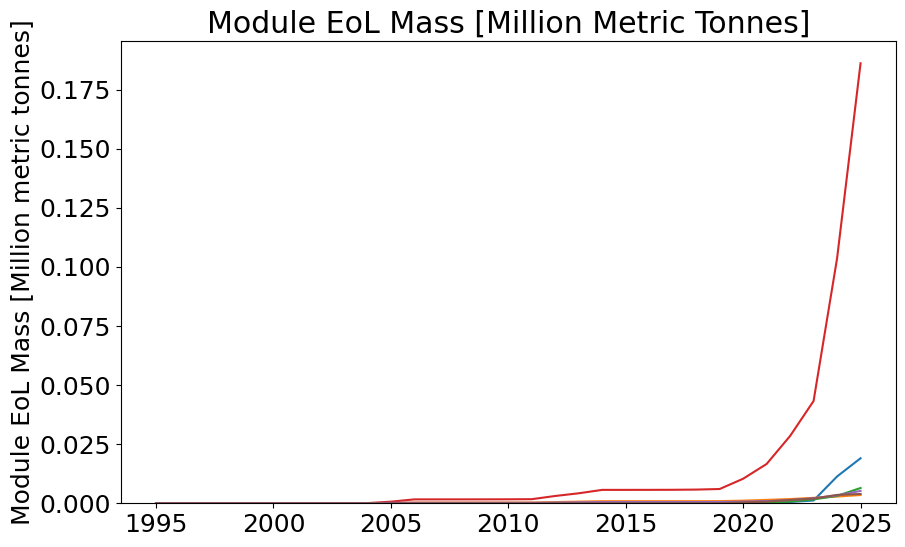

In [60]:
eol_module_tonnes = sim1_cumu.filter(like='WasteEOL_Module')
plt.plot(eol_module_tonnes/1e6)
plt.ylim(0,)
plt.title('Module EoL Mass [Million Metric Tonnes]')
plt.ylabel('Module EoL Mass [Million metric tonnes]')

# PV Fleets Degradation by PV Climate Zone

create baseline input files for PV Fleets degradation spread for each country. Do as separate simulation, just in case.

In [61]:
#fleets_deg_rates = pd.read_csv(os.path.join(supportMatfolder, 'PVFleets_Degradation_Data.csv'))
PVCZ_deg_rates
#df_baseline_module_world = pd.read_csv(moduleFile_m)


,Years before reaching 80%,Degradation Rate,USA PV Fleets,USA PV Fleets (H method),France (T3:T4),Italy (T4:T5),Spain (T4:T5:T6),Germany (T3),Netherlands (T3)
0,100,-0.01,0.00,9.06,9.520,7.050,8.15,10.34,10.34
1,100,-0.20,18.42,12.71,12.735,9.720,11.61,15.38,15.38
2,50,-0.40,10.06,15.26,14.550,15.895,15.40,14.40,14.40
3,33,-0.60,12.30,14.19,12.705,15.785,14.65,12.37,12.37
4,25,-0.80,11.62,11.93,10.250,14.585,13.37,10.93,10.93
5,20,-1.00,10.22,9.15,9.220,9.365,9.14,8.70,8.70
6,16,-1.20,8.51,7.61,7.675,8.540,8.11,7.26,7.26
7,14,-1.40,6.90,4.43,4.885,5.025,4.64,3.86,3.86
8,12,-1.60,5.37,4.08,4.820,4.125,3.99,3.73,3.73
9,11,-1.80,4.70,2.95,3.290,3.085,2.97,2.75,2.75


In [77]:
country_deploy_total = deployment_bycountry_raw.loc[1995:,'ITALY']
df_module_country = df_baseline_module_world.copy() #make copy of the world df for the country
df_module_country.loc[1:,'new_Installed_Capacity_[MW]'] = 0.0 #wipe the install
df_module_country.loc[1:len(country_deploy_total),'new_Installed_Capacity_[MW]'] = country_deploy_total.values #overwrite with country data

In [78]:
df_module_country

,year,new_Installed_Capacity_[MW],mod_eff,mod_reliability_t50,mod_reliability_t90,mod_degradation,mod_lifetime,mod_MFG_eff,mod_Repair,mod_MerchantTail,...,mod_EOL_pg1_landfill,mod_EOL_pg2_stored,mod_EOL_pg3_reMFG,mod_EOL_pg4_recycled,mod_EOL_reMFG_yield,mod_EOL_sp_reMFG_recycle,mod_EOL_pb1_landfill,mod_EOL_pb2_stored,mod_EOL_pb3_reMFG,mod_EOL_pb4_recycled
0,year,MW,%,years,years,%,years,%,%,%,...,%,%,%,%,%,%,%,%,%,%
1,1995,2,12.5,16,21,0.75,10,95,0,0,...,60,0,0,40,0,100,60,0,0,40
2,1996,0,12.7,16,21,0.75,10,95,0,0,...,60,0,0,40,0,100,60,0,0,40
3,1997,1,12.88,18,20,0.75,15,95,0,0,...,60,0,0,40,0,100,60,0,0,40
4,1998,1,13.06,18,20,0.75,15,95,0,0,...,60,0,0,40,0,100,60,0,0,40
5,1999,1,13.24,18,20,0.75,15,95,0,0,...,60,0,0,40,0,100,60,0,0,40
6,2000,1,13.42,22.5,24,0.75,20,95,0,0,...,60,0,0,40,0,100,60,0,0,40
7,2001,1,13.6,22.5,24,0.75,20,95,0,0,...,60,0,0,40,0,100,60,0,0,40
8,2002,2,13.72222222,22.5,24,0.75,20,95,0,0,...,60,0,0,40,0,100,60,0,0,40
9,2003,4,13.84444444,22.5,24,0.75,20,96,0,0,...,60,0,0,40,0,100,60,0,0,40


### Create the module files to read in for each country and each degradation cohort within the country
This section is just manipulating and creating csvs

In [152]:
deg_baselines_filenames = [] # for later use
deg_rate_log = [] #for later use

df_baseline_module_world = pd.DataFrame(pd.read_csv(moduleFile_m_Si)) #create a template to copy

for country in countries:
    #prep the total country deployment for multiplication later
    country_deploy_total = deployment_bycountry_raw.loc[1995:,country] #extract the country total deployment from PVPS file
    df_module_country = df_baseline_module_world.copy() #make copy of the world df for the country
    df_module_country.loc[1:,'new_Installed_Capacity_[MW]'] = 0.0 #wipe the install
    df_module_country.loc[1:len(country_deploy_total),'new_Installed_Capacity_[MW]'] = country_deploy_total.values #overwrite with country data

    country_pvcz_cohort = PVCZ_deg_rates.filter(regex=re.compile(country, re.IGNORECASE)) #select the country specific cohort:deg rate column
    deg_col = PVCZ_deg_rates['Degradation Rate']
    pvcz_country_deg_cohort = pd.concat([deg_col,country_pvcz_cohort], axis=1) #attach cohort to the degradation rate
    
    for row in pvcz_country_deg_cohort.index:
        df_module_country_cohort = df_module_country.copy() #make copy df of country specific deployment
        
        deg_rate = pvcz_country_deg_cohort.loc[row]['Degradation Rate'] #*-1 #extract deg rate, already negative
        cohort_percent = pvcz_country_deg_cohort.iloc[row,1]/100 #extract fraction for cohort
        deg_rate_log.append(deg_rate)
    
        #modify the cohort deployment, fix label
        cohort_deploy = pd.to_numeric(df_module_country.loc[1:,'new_Installed_Capacity_[MW]'], errors='coerce')*cohort_percent 
        df_module_country_cohort['new_Installed_Capacity_[MW]'] = cohort_deploy
        #df_module_country_cohort.loc[1:,'new_Installed_Capacity_[MW]'] = 'MW'
    
        #modify deg rate
        df_module_country_cohort.loc[1:,'mod_degradation'] = deg_rate
        
        #save out a file for each deg rate cohort
        out_name = f"baseline_modules_mass_{country}_deg_{abs(deg_rate):0.1f}.csv"
        out_path = os.path.join(testfolder, 'input', country) #save to the study folder
        if not os.path.exists(out_path):
            os.makedirs(out_path)
        deg_baselines_filenames.append(out_name) #internal to python record
        df_module_country_cohort.to_csv(os.path.join(out_path, out_name), index=False)


In [56]:
#prep list of files as a series that can be called/iterated
deg_baselines_filenames_series = pd.Series(deg_baselines_filenames)
deg_rate_log_series = pd.Series(deg_rate_log)
df_DegRate_FilePath= pd.concat([deg_rate_log_series,deg_baselines_filenames_series], axis=1)
#df_DegRate_FilePath.columns=['DegRate','FilePath']
df_DegRate_FilePath

,0,1
0,5.2,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...
1,4.2,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...
2,3.4,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...
3,3.2,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...
4,3.0,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...
5,2.8,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...
6,2.6,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...
7,2.4,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...
8,2.2,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...
9,2.0,C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_I...


In [57]:
# add mass flows for each of the cohort baselines as scenarios
sim2 = PV_ICE.Simulation(name='PVFleets', path=testfolder)

for row in df_DegRate_FilePath.index:
    deg_scen = f"deg_{str(df_DegRate_FilePath.loc[row][0])}"
    filepath = df_DegRate_FilePath.loc[row][1]
    print(deg_scen)#, filepath)
    sim2.createScenario(name=deg_scen, massmodulefile=filepath)
    sim2.scenario[deg_scen].addMaterials(['glass', 'silicon', 'silver', 'copper', 'aluminium_frames', 'encapsulant', 'backsheet'])

path = C:\Users\hmirletz\Documents\GitHub\PV_ICE\PV_ICE\PV_ICE\TEMP\2026-08-forTCurtis
Baseline folder directed to default:  C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\baselines
deg_5.2
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
Adding Mass AND Energy files for:  glass
Adding Mass AND Energy files for:  silicon
Adding Mass AND Energy files for:  silver
Adding Mass AND Energy files for:  copper
Adding Mass AND Energy files for:  aluminium_frames
Adding Mass AND Energy files for:  encapsulant
Adding Mass AND Energy files for:  backsheet
deg_4.2
No energy module file passed. If desired, pass one of the following options:  ['baseline_modules_energy.csv']
Adding Mass AND Energy files for:  glass
Adding Mass AND Energy files for:  silicon
Adding Mass AND Energy files for:  silver
Adding Mass AND Energy files for:  copper
Adding Mass AND Energy files for:  aluminium_frames
Adding Mass AND Energy files f

In [58]:
#run mass flow
sim2.scenario.keys()

dict_keys(['deg_5.2', 'deg_4.2', 'deg_3.4', 'deg_3.2', 'deg_3.0', 'deg_2.8', 'deg_2.6', 'deg_2.4', 'deg_2.2', 'deg_2.0', 'deg_1.8', 'deg_1.6', 'deg_1.4', 'deg_1.2', 'deg_1.0', 'deg_0.8', 'deg_0.6', 'deg_0.4', 'deg_0.2'])

In [60]:
sim2.calculateMassFlow() #takes a min

>>>> Calculating Material Flows <<<<

Working on Scenario:  deg_5.2
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silicon
==> Working on Material :  silver
==> Working on Material :  copper
==> Working on Material :  aluminium_frames
==> Working on Material :  encapsulant
==> Working on Material :  backsheet
Working on Scenario:  deg_4.2
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silicon
==> Working on Material :  silver
==> Working on Material :  copper
==> Working on Material :  aluminium_frames
==> Working on Material :  encapsulant
==> Working on Material :  backsheet
Working on Scenario:  deg_3.4
********************
Finished Area+Power Generation Calculations
==> Working on Material :  glass
==> Working on Material :  silicon
==> Working on Material :  silver
==> Working on Material :  copper
==> Working on Material :  al

In [61]:
sim2_annual, sim2_cumu = sim2.aggregateResults()

C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:2164: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  USyearly[nicekey+'_'+mat+'_'+self.name+'_'+scen] = self.scenario[scen].material[mat].matdataOut_m[keywd]
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:2164: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  USyearly[nicekey+'_'+mat+'_'+self.name+'_'+scen] = self.scenario[scen].material[mat].matdataOut_m[keywd]
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\mai

In [62]:
sim2.scenario['deg_4.2'].dataOut_m.keys()

Index(['Area', 'Cumulative_Active_Area', 'EOL_BadStatus', 'EOL_Landfill0',
       'EOL_PATHS', 'EOL_PG', 'Effective_Capacity_[W]', 'Landfill_0_ProjLife',
       'MerchantTail_Area', 'MerchantTail_[W]', 'ModuleTotal_MFG', 'P2_stored',
       'P3_reMFG', 'P4_recycled', 'PB1_landfill', 'PB2_stored', 'PB3_reMFG',
       'PB3_reMFG_unyield', 'PB3_reMFG_yield', 'PB4_recycled', 'PG1_landfill',
       'PG2_stored', 'PG3_reMFG', 'PG3_reMFG_unyield', 'PG3_reMFG_yield',
       'PG4_recycled', 'Power_Degraded_[W]', 'Repaired_Area', 'Repaired_[W]',
       'Resold_Area', 'Resold_[W]', 'WeibullParams',
       'Yearly_Sum_Area_EOLby_Degradation', 'Yearly_Sum_Area_EOLby_Failure',
       'Yearly_Sum_Area_EOLby_ProjectLifetime', 'Yearly_Sum_Area_PathsBad',
       'Yearly_Sum_Area_PathsGood', 'Yearly_Sum_Area_atEOL',
       'Yearly_Sum_Power_EOLby_Degradation', 'Yearly_Sum_Power_EOLby_Failure',
       'Yearly_Sum_Power_EOLby_ProjectLifetime', 'Yearly_Sum_Power_PathsBad',
       'Yearly_Sum_Power_PathsGood

In [63]:
sim2_cumu.keys()

Index(['VirginStock_glass_PVFleets_deg_5.2_[Tonnes]',
       'VirginStock_silicon_PVFleets_deg_5.2_[Tonnes]',
       'VirginStock_silver_PVFleets_deg_5.2_[Tonnes]',
       'VirginStock_copper_PVFleets_deg_5.2_[Tonnes]',
       'VirginStock_aluminium_frames_PVFleets_deg_5.2_[Tonnes]',
       'VirginStock_encapsulant_PVFleets_deg_5.2_[Tonnes]',
       'VirginStock_backsheet_PVFleets_deg_5.2_[Tonnes]',
       'VirginStock_Module_PVFleets_deg_5.2_[Tonnes]',
       'WasteAll_glass_PVFleets_deg_5.2_[Tonnes]',
       'WasteAll_silicon_PVFleets_deg_5.2_[Tonnes]',
       ...
       'newInstalledCapacity_PVFleets_deg_2.0_[MW]',
       'newInstalledCapacity_PVFleets_deg_1.8_[MW]',
       'newInstalledCapacity_PVFleets_deg_1.6_[MW]',
       'newInstalledCapacity_PVFleets_deg_1.4_[MW]',
       'newInstalledCapacity_PVFleets_deg_1.2_[MW]',
       'newInstalledCapacity_PVFleets_deg_1.0_[MW]',
       'newInstalledCapacity_PVFleets_deg_0.8_[MW]',
       'newInstalledCapacity_PVFleets_deg_0.6_[MW]',
   

In [64]:
df_WasteEOL_allFleetsDegscen = pd.DataFrame(sim2_cumu.filter(like='WasteEOL_Module').sum(axis=1)).loc[:2050]
df_WasteEOL_allFleetsDegscen.columns=['WasteEOL_Module_[tonnes]']

In [49]:
eol_cumu_all = sim1_cumu.filter(like='WasteEOL')
eol_cumu_all_mats_2050 = eol_cumu_all.loc[:2050].iloc[:,:7]
#eol_cumu_all_mats_2050

In [50]:
eol_cumu_all_mats_2050.columns

Index(['WasteEOL_glass_sim1_base_[Tonnes]',
       'WasteEOL_silver_sim1_base_[Tonnes]',
       'WasteEOL_silicon_sim1_base_[Tonnes]',
       'WasteEOL_copper_sim1_base_[Tonnes]',
       'WasteEOL_aluminium_frames_sim1_base_[Tonnes]',
       'WasteEOL_encapsulant_sim1_base_[Tonnes]',
       'WasteEOL_backsheet_sim1_base_[Tonnes]'],
      dtype='object')

(2000.0, 2051.0)

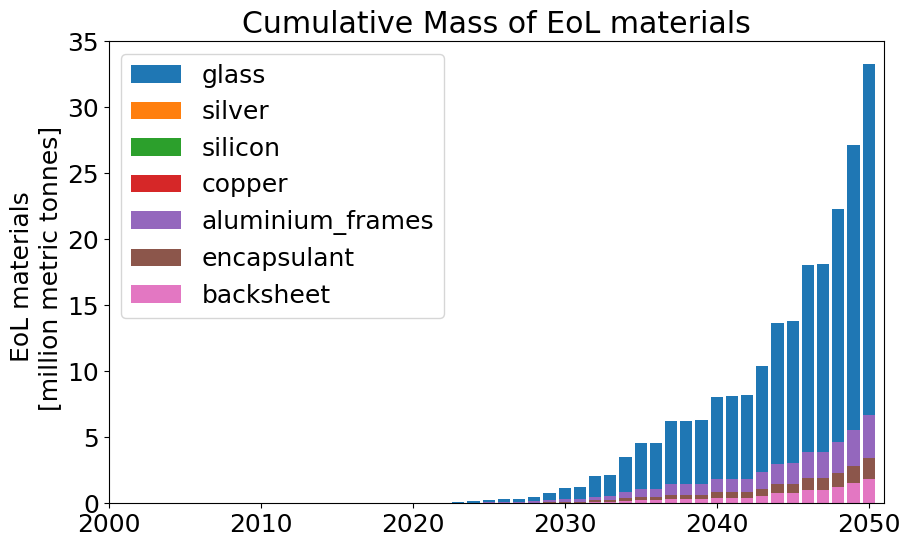

In [51]:
for mat in eol_cumu_all_mats_2050.columns:
    plt.bar(eol_cumu_all_mats_2050.index, eol_cumu_all_mats_2050[mat]/1e6)
plt.legend(MATERIALS)
plt.ylabel('EoL materials \n [million metric tonnes]')
plt.title('Cumulative Mass of EoL materials')
plt.ylim(0,35)
plt.xlim(2000,2051)

In [52]:
eos_cumu_mats_milltonne = eol_cumu_all_mats_2050/1e6
eos_cumu_mats_milltonne.to_csv(os.path.join(testfolder, 'output_cumu_mats_milltonne.csv'))

## in number of modules and GWs

In [53]:
sim1.scenario['base'].dataOut_m.keys()

KeyError: 'base'

In [ ]:
modulearea_eol_millionm2 = sim1.scenario['base'].dataOut_m['Yearly_Sum_Area_atEOL'].cumsum()/1e6

In [ ]:
plt.bar(sim1.scenario['base'].dataIn_m['year'], modulearea_eol_millionm2)
plt.ylim(0,)
plt.title('Cumulative Area at EoL in 1e6 m2')
plt.ylabel('million meters^2')

In [ ]:
eol_modules_smaller = sim1.scenario['base'].dataOut_m['Yearly_Sum_Area_atEOL'].cumsum()/1.6
eol_modules_larger = sim1.scenario['base'].dataOut_m['Yearly_Sum_Area_atEOL'].cumsum()/2.75
df_modules = pd.concat([eol_modules_smaller, eol_modules_larger], axis=1)
#, columns=
df_modules.columns = ['Cumulative Modules 1.6m2','Cumulative Modules 2.75m2']
df_modules.index = sim1.scenario['base'].dataIn_m['year']
df_modules

In [ ]:
cumu_power_eol = pd.Series(sim1.scenario['base'].dataOut_m['Yearly_Sum_Power_atEOL'].cumsum()/1e9)#GW
cumu_power_eol.index = sim1.scenario['base'].dataIn_m['year']
df_modules['Cumulative Power at EoL [GW]'] = cumu_power_eol

In [54]:
df_modules.to_csv(os.path.join(testfolder, 'output_modules_power_cumuEoL.csv'))

In [59]:
#trim to start in 2000, this trims module and materials
#had to specify and end year, cannot use to extend
sim2.trim_Years(startYear=2000, endYear=2100)
sim2.scenMod_noCircularity()

Trimming and extending  deg_5.2
No energy data loaded. Skipping for all next scenarios and materials
deg_5.2 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100
Trimming and extending  deg_4.2
deg_4.2 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100
Trimming and extending  deg_3.4


C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1873: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  extended = pd.concat([reduced,add]) #concat the trimmed early years with the new extended years
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1876: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  extended.ffill(inplace=True) #forward fill columns
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays o

deg_3.4 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100
Trimming and extending  deg_3.2
deg_3.2 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100
Trimming and extending  deg_3.0


C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  extended.ffill(inplace=True) #forward fill columns
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  extended.ffill(inplace=True) #forward fill columns
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version

deg_3.0 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100
Trimming and extending  deg_2.8


C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  extended.ffill(inplace=True) #forward fill columns
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  extended.ffill(inplace=True) #forward fill columns
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1873: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, thi

... (6 outputs left out)

deg_1.0 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100
Trimming and extending  deg_0.8
deg_0.8 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100
Trimming and extending  deg_0.6
deg_0.6 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100
Trimming and extending  deg_0.4


C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  extended.ffill(inplace=True) #forward fill columns
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  extended.ffill(inplace=True) #forward fill columns
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version

deg_0.4 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100
Trimming and extending  deg_0.2
deg_0.2 backsheet : Data trimmed for Mass, years now encompass  2000  to  2100


C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  extended.ffill(inplace=True) #forward fill columns
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  extended.ffill(inplace=True) #forward fill columns
C:\Users\hmirletz\AppData\Local\anaconda3\Lib\site-packages\PV_ICE\main.py:1947: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version

Text(0, 0.5, 'EoS Module mass\n[Million Metric tonnes]')

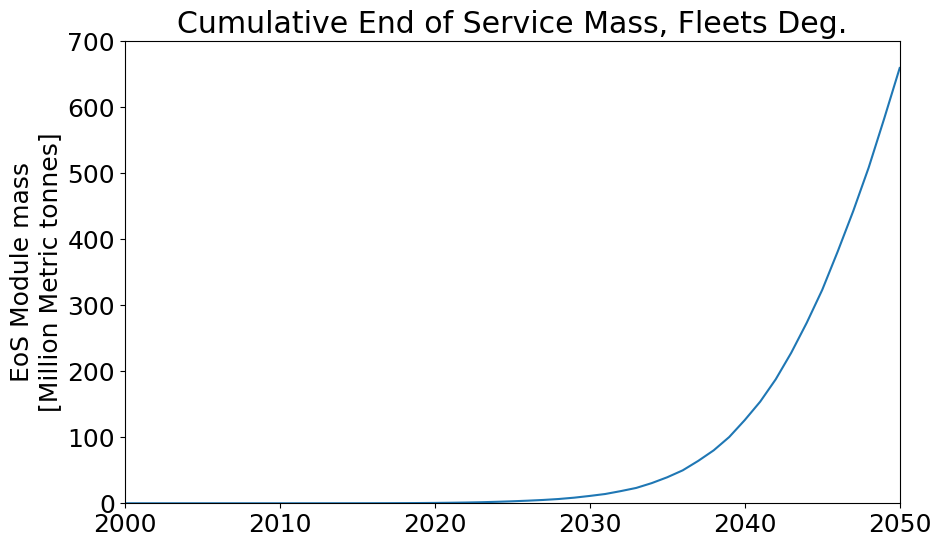

In [65]:
plt.plot(df_WasteEOL_allFleetsDegscen/1e6)
plt.ylim(0,700)
plt.xlim(2000,2050)
plt.title('Cumulative End of Service Mass, Fleets Deg.')
plt.ylabel('EoS Module mass\n[Million Metric tonnes]')

In [74]:
sim2_EoS_mats_cumu_mass = pd.DataFrame()
for mats in MATERIALS:
    sim2_EoS_mats_cumu_mass[mats+'_millionMetricTonne'] = sim2_cumu.filter(regex='WasteEOL_'+mats).sum(axis=1).loc[:2050]/1e6

#sim2_EoS_mats_cumu_mass.tail()

,glass_millionMetricTonne,silver_millionMetricTonne,silicon_millionMetricTonne,copper_millionMetricTonne,aluminium_frames_millionMetricTonne,encapsulant_millionMetricTonne,backsheet_millionMetricTonne
year,,,,,,,
2046,302.216909,0.076643,10.697339,0.219715,36.755843,21.499006,9.984531
2047,351.365080,0.086227,12.338576,0.253896,42.374003,24.809561,11.408207
2048,404.489553,0.096452,14.106604,0.290604,48.434282,28.377477,12.936466
2049,463.961854,0.108345,16.112321,0.331940,55.294677,32.422015,14.687329
2050,525.595692,0.120082,18.160369,0.374382,62.308887,36.549245,16.438206


In [78]:
df_WasteEOL_allFleetsDegscen_MMT = df_WasteEOL_allFleetsDegscen/1e6
df_WasteEOL_allFleetsDegscen_MMT.columns=['WasteEOL_Module_[million metric tonnes]']
df_WasteEOS_allFleetsDeg_Mats_MMT = pd.concat([df_WasteEOL_allFleetsDegscen_MMT, sim2_EoS_mats_cumu_mass], axis=1)
df_WasteEOS_allFleetsDeg_Mats_MMT.to_csv(os.path.join(testfolder, 'output_PVFleetsDeg_cumu_mass_mats_MMT.csv'))

In [100]:
df_areaEOS_sim2 = pd.DataFrame()
for scen in sim2.scenario.keys():
    df_areaEOS_sim2[scen] = sim2.scenario[scen].dataOut_m['Yearly_Sum_Area_atEOL']

In [106]:
df_areaEOS_sim2_all = df_areaEOS_sim2.sum(axis=1).cumsum() #sum the scens together, then cumulative area
df_areaEOS_cumu_smallModule = df_areaEOS_sim2_all/1.6
df_areaEOS_cumu_largeModule = df_areaEOS_sim2_all/2.75

df_ModulesEOS_sim2 = pd.concat([df_areaEOS_cumu_smallModule, df_areaEOS_cumu_largeModule],axis=1)
df_ModulesEOS_sim2.columns = ['Cumulative Modules 1.6m2','Cumulative Modules 2.75m2']
df_ModulesEOS_sim2.index = sim1.scenario['base'].dataIn_m['year']
df_ModulesEOS_sim2

,Cumulative Modules 1.6m2,Cumulative Modules 2.75m2
year,,
2000,0.000000e+00,0.000000e+00
2001,0.000000e+00,0.000000e+00
2002,0.000000e+00,0.000000e+00
2003,0.000000e+00,0.000000e+00
2004,8.921359e-09,5.190609e-09
...,...,...
2096,2.990099e+11,1.739694e+11
2097,3.039118e+11,1.768214e+11
2098,3.088138e+11,1.796735e+11


In [107]:
df_powerEOS_sim2 = pd.DataFrame()
for scen in sim2.scenario.keys():
    df_powerEOS_sim2[scen] = sim2.scenario[scen].dataOut_m['Yearly_Sum_Power_atEOL']

In [110]:
cumu_power_eos_sim2 = pd.Series(df_powerEOS_sim2.sum(axis=1).cumsum()/1e9) #sum the scens together, then cumulative power, in GW
cumu_power_eos_sim2.index = sim1.scenario['base'].dataIn_m['year']
cumu_power_eos_sim2

year
2000    0.000000e+00
2001    0.000000e+00
2002    0.000000e+00
2003    0.000000e+00
2004    1.839269e-15
            ...     
2096    9.641677e+04
2097    9.804608e+04
2098    9.967539e+04
2099    1.013047e+05
2100    1.029340e+05
Length: 101, dtype: float64

In [111]:
df_ModulesEOS_sim2['Cumulative Power at EoS PVFleets [GW]'] = cumu_power_eos_sim2

In [114]:
df_ModulesEOS_sim2.loc[:2050,].to_csv(os.path.join(testfolder, 'output_PVFleetsDeg_cumu_modulesAndPower.csv'))